<font size=7 color="#5499C7" >Final Project</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

<font size=7 color="#5499C7">Context</font>

This block initializes the environment and dependencies required for an image-based deep learning workflow.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

The code only imports standard libraries for file handling, math, visualization, and deep learning. PyTorch and torchvision support model training and image processing, while `kagglehub` is intended for dataset downloading. No logic is executed here; this block prepares the runtime for subsequent dataset, model, and training definitions.

</font>

In [1]:
import os
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

import kagglehub

<font size=7 color="#5499C7">Context</font>

This block defines global configuration and runtime controls for a pix2pix-style image-to-image translation experiment.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

Reproducibility is enforced via a fixed random seed and optional deterministic behavior. The configuration supports a **FAST_RUN** mode that reduces dataset size and batch size for quick testing. Training is set up for the **edges2shoes** paired dataset with a fixed image resolution of 256×256 and standard pix2pix hyperparameters (Adam optimizer with L1 regularization).

Early stopping is enabled and can monitor reconstruction or perceptual metrics. Optional input corruption is included for restoration-style experiments but is disabled by default. Checkpointing, sampling, and evaluation limits are configurable, and the device is selected automatically based on CUDA availability.

</font>

In [2]:
# Reproducibility
SEED = 42
DETERMINISTIC = True

# Runtime controls
FAST_RUN = False  # True: smaller subset + lower resolution for quick smoke tests
EPOCHS = 67 # Smaller epochs for faster runs
MIXED_PRECISION = False

# Dataset selection
DATASET_SLUG = "vikramtiwari/pix2pix-dataset"
DATASET_NAME = "edges2shoes"
DIRECTION = "AtoB"

# Image sizes and batching
FULL_IMG_SIZE = 256
FAST_IMG_SIZE = 256
IMG_SIZE = FAST_IMG_SIZE if FAST_RUN else FULL_IMG_SIZE

FULL_BATCH_SIZE = 16
FAST_BATCH_SIZE = 4
BATCH_SIZE = FAST_BATCH_SIZE if FAST_RUN else FULL_BATCH_SIZE

# Data loading limits (None = full split)
FAST_TRAIN_LIMIT = 200
FAST_VAL_LIMIT = 80
FAST_TEST_LIMIT = 80
MAX_TRAIN_SAMPLES = FAST_TRAIN_LIMIT if FAST_RUN else None
MAX_VAL_SAMPLES = FAST_VAL_LIMIT if FAST_RUN else None
MAX_TEST_SAMPLES = FAST_TEST_LIMIT if FAST_RUN else None

# Training hyperparameters
LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999
LAMBDA_L1 = 100.0

# Training loop controls
MAX_STEPS_PER_EPOCH = 50 if FAST_RUN else None
LOG_EVERY_N_STEPS = 20


# Early stopping
USE_EARLY_STOPPING = True
EARLY_STOP_METRIC = "l1"  # options: "l1", "psnr", "ssim"
EARLY_STOP_MODE = "min"   # "min" for L1, "max" for PSNR/SSIM
EARLY_STOP_PATIENCE = 5
EARLY_STOP_MIN_DELTA = 1e-4

# Optional corruption settings (for restoration tasks)
CORRUPT_INPUT = False
CORRUPTION_MAX_FRAC = 0.4
CORRUPTION_NOISE_STD = 0.0

# Evaluation settings
EVAL_MAX_BATCHES = 10 if FAST_RUN else None
BASELINE_EVAL_MAX_BATCHES = 5 if FAST_RUN else None

# Checkpointing and outputs
CHECKPOINT_DIR = "/kaggle/working"
SAMPLE_DIR = "/kaggle/working/samples"
SAVE_SAMPLE_EVERY_N_STEPS = 100
SAVE_CHECKPOINT_EVERY_EPOCH = True
LOAD_CHECKPOINT = False

# DataLoader performance
NUM_WORKERS = 0 if FAST_RUN else 2
PIN_MEMORY = True

# Device
DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"

<font size=7 color="#5499C7">Pix2Pix Image Translation</font>

This notebook implements a from-scratch pix2pix pipeline for paired image-to-image translation on edges2shoes.


<font size=6 color="#5499C7">Goal</font>
<font size=5>

Train a U-Net generator and PatchGAN discriminator from scratch, evaluate with PSNR/SSIM, and provide an interactive demo.

</font>


<font size=7 color="#5499C7">Assumptions</font>

A few reasonable assumptions are documented to keep the notebook self-contained and runnable.


<font size=6 color="#5499C7">Notes</font>
<font size=5>

The task is treated as paired translation (edges -> shoes). Synthetic corruption is disabled by default (CORRUPT_INPUT=False) but can be enabled if a restoration setup is required. Metrics are computed on images scaled to [0, 1].

</font>


In [3]:
def set_seed(seed, deterministic=True):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED, DETERMINISTIC)
DEVICE = torch.device(DEVICE_STR)
print("Device:", DEVICE)
print("FAST_RUN:", FAST_RUN)

os.makedirs(SAMPLE_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

Device: cuda
FAST_RUN: False


<font size=7 color="#5499C7">Dataset</font>

We use the Kaggle pix2pix dataset and select the edges2shoes subset.


<font size=6 color="#5499C7">Loading</font>
<font size=5>

The dataset is downloaded with kagglehub and a fallback search checks typical Kaggle input locations.

</font>


In [4]:
candidates = [
    Path("/kaggle/input/pix2pix-dataset/edges2shoes/edges2shoes"),
    Path("/kaggle/input/pix2pix-dataset/edges2shoes"),
    Path("/kaggle/input/pix2pix-dataset"),
]

dataset_root = None
for c in candidates:
    if (c / "train").exists() and (c / "val").exists():
        dataset_root = c
        break

if dataset_root is None:
    # fallback: download
    path = kagglehub.dataset_download(DATASET_SLUG)
    dataset_root = Path(path)
    # if kagglehub returns a parent, search one level
    if not (dataset_root / "train").exists():
        for child in dataset_root.glob("**/train"):
            dataset_root = child.parent
            break

if dataset_root is None or not (dataset_root / "train").exists():
    raise FileNotFoundError("Could not find a folder with train/val splits.")

print("Using dataset root:", dataset_root)
print("Train files:", len(list((dataset_root / "train").glob("*"))))
print("Val files:", len(list((dataset_root / "val").glob("*"))))

Using dataset root: /kaggle/input/pix2pix-dataset/edges2shoes/edges2shoes


Train files: 49825
Val files: 200


<font size=7 color="#5499C7">Context</font>

This block defines data corruption logic and a custom Dataset for pix2pix-style paired image translation.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

Optional corruption simulates occlusion and noise on the input image and produces a corresponding mask. The dataset class splits each paired image into input–target halves, supports direction control (A→B or B→A), simple augmentation, and optional corruption. Train, validation, and test loaders are created with configurable limits and batching for efficient experimentation.

</font>

In [5]:
def apply_corruption(img, max_frac=CORRUPTION_MAX_FRAC, noise_std=CORRUPTION_NOISE_STD):
    if max_frac <= 0 and noise_std <= 0:
        return img, Image.new("L", img.size, 0)

    np_img = np.array(img).astype(np.float32)
    h, w = np_img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    if max_frac > 0:
        cut_w = max(1, int(w * random.uniform(0.1, max_frac)))
        cut_h = max(1, int(h * random.uniform(0.1, max_frac)))
        x0 = random.randint(0, max(0, w - cut_w))
        y0 = random.randint(0, max(0, h - cut_h))
        np_img[y0:y0 + cut_h, x0:x0 + cut_w] = 0
        mask[y0:y0 + cut_h, x0:x0 + cut_w] = 1

    if noise_std > 0:
        noise = np.random.normal(0, noise_std, np_img.shape).astype(np.float32)
        np_img = np.clip(np_img + noise, 0, 255)
        mask[:, :] = 1

    corrupted = Image.fromarray(np_img.astype(np.uint8))
    mask_img = Image.fromarray((mask * 255).astype(np.uint8))
    return corrupted, mask_img

class Pix2PixDataset(Dataset):
    def __init__(self, root, split, img_size, max_samples=None, augment=False, apply_corruption=False, direction="AtoB"):
        self.root = Path(root)
        self.split = split
        self.files = sorted((self.root / split).glob("*"))
        if max_samples is not None:
            self.files = self.files[:max_samples]
        self.augment = augment
        self.apply_corruption = apply_corruption
        self.direction = direction

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=Image.BICUBIC),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=Image.NEAREST),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert("RGB")
        w, h = img.size
        w2 = w // 2
        img_A = img.crop((0, 0, w2, h))
        img_B = img.crop((w2, 0, w, h))

        if self.direction == "BtoA":
            img_A, img_B = img_B, img_A

        if self.augment and random.random() < 0.5:
            img_A = img_A.transpose(Image.FLIP_LEFT_RIGHT)
            img_B = img_B.transpose(Image.FLIP_LEFT_RIGHT)

        mask = Image.new("L", img_A.size, 0)
        if self.apply_corruption:
            img_A, mask = apply_corruption(img_A)

        img_A = self.transform(img_A)
        img_B = self.transform(img_B)
        mask = self.mask_transform(mask)
        return img_A, img_B, mask

test_split = "test" if (dataset_root / "test").exists() else "val"
if test_split == "val":
  print("No test split found; using val as test.")

train_ds = Pix2PixDataset(
    dataset_root,
    split="train",
    img_size=IMG_SIZE,
    max_samples=MAX_TRAIN_SAMPLES,
    augment=True,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)
val_ds = Pix2PixDataset(
    dataset_root,
    split="val",
    img_size=IMG_SIZE,
    max_samples=MAX_VAL_SAMPLES,
    augment=False,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)
test_ds = Pix2PixDataset(
    dataset_root,
    split=test_split,
    img_size=IMG_SIZE,
    max_samples=MAX_TEST_SAMPLES,
    augment=False,
    apply_corruption=CORRUPT_INPUT,
    direction=DIRECTION,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Train/Val/Test sizes: {len(train_ds)}/{len(val_ds)}/{len(test_ds)}")

No test split found; using val as test.


Train/Val/Test sizes: 49825/200/200


<font size=7 color="#5499C7">Direction Sanity Check</font>

Run this once before training to verify the input/target order.


<font size=6 color="#5499C7">Check</font>
<font size=5>

If the input does not look like edges and the ground truth does not look like shoes, set DIRECTION = "BtoA" and rerun.

</font>

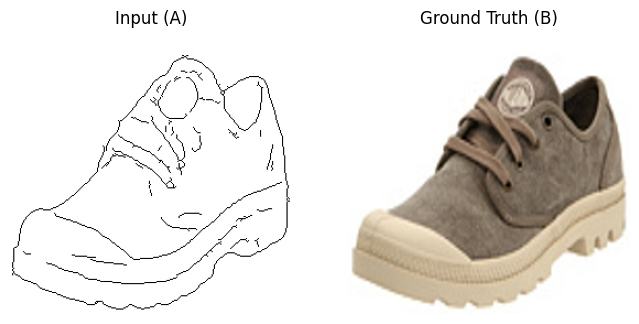

If the input is not edges and the ground truth is not shoes, set DIRECTION = "BtoA" and rerun.


In [6]:
@torch.no_grad()
def show_direction_sanity_check(split="val", index=0):
    ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
    ds = ds_map[split]
    if len(ds) == 0:
        print(f"No samples available in {split} split.")
        return

    index = min(index, len(ds) - 1)
    real_A, real_B, _ = ds[index]

    def to_img(t):
        t = (t * 0.5 + 0.5).clamp(0, 1)
        return np.transpose(t.numpy(), (1, 2, 0))

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax in axes:
        ax.axis("off")

    axes[0].imshow(to_img(real_A))
    axes[0].set_title("Input (A)")
    axes[1].imshow(to_img(real_B))
    axes[1].set_title("Ground Truth (B)")
    plt.show()

    print("If the input is not edges and the ground truth is not shoes, set DIRECTION = \"BtoA\" and rerun.")

show_direction_sanity_check(split="val", index=0)

<font size=7 color="#5499C7">Model</font>

The generator is a U-Net and the discriminator is a 70x70 PatchGAN, implemented from scratch.

A **GAN (specifically a conditional GAN like pix2pix)** is well-suited for picture-to-picture translation on the pix2pix datasets for these reasons:

1. **Paired data availability**
   The datasets provide aligned input–output image pairs (e.g., edges → photos, maps → aerial images). Conditional GANs are designed to learn a direct mapping from an input image to its corresponding target image using this paired supervision.

2. **Adversarial loss improves realism**
   Pixel-wise losses (L1/L2) alone tend to produce blurry results. The GAN discriminator learns what realistic target images look like given an input, pushing the generator to produce sharper and more realistic outputs.

3. **Preservation of structural correspondence**
   Because the discriminator evaluates image pairs (input, output), the model learns to respect the spatial and semantic structure present in the input image, which is essential for image-to-image translation tasks.

4. **Effective modeling of high-frequency details**
   Pix2pix uses a PatchGAN discriminator that focuses on local image patches, encouraging correct textures, edges, and fine details that are important in datasets like facades, cityscapes, and edges-to-photos.

5. **Balanced objectives**
   The combination of adversarial loss (for realism) and L1 loss (for correctness and alignment) makes GANs particularly effective for these datasets, achieving both visually plausible and structurally accurate translations.

In short, GANs match the supervised, structured, and realism-critical nature of the pix2pix datasets better than purely regression-based models.


<font size=6 color="#5499C7">Architecture</font>
<font size=5>

We follow the original pix2pix design: a U-Net encoder-decoder with skip connections and a convolutional PatchGAN discriminator that conditions on input-target pairs.

</font>

<font size=7 color="#5499C7">Context</font>

This block defines the generator and discriminator architectures for a pix2pix-style conditional GAN.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

The generator is a U-Net with encoder–decoder symmetry and skip connections to preserve spatial structure during translation. Downsampling uses strided convolutions, while upsampling uses transposed convolutions with optional dropout. The discriminator is a PatchGAN that judges local realism on concatenated input–output pairs. Weights are initialized with a normal distribution following standard GAN practice.

</font>

In [7]:
class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)
        ]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat([x, skip], dim=1)

class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512)
        self.down5 = UNetDown(512, 512)
        self.down6 = UNetDown(512, 512)
        self.down7 = UNetDown(512, 512)
        self.down8 = UNetDown(512, 512, normalize=False)

        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)
        return self.final(u7)

class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        def disc_block(in_filters, out_filters, normalize=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, 2, 1, bias=False)]
            if normalize:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *disc_block(in_channels * 2, 64, normalize=False),
            *disc_block(64, 128),
            *disc_block(128, 256),
            *disc_block(256, 512),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1),
        )

    def forward(self, img_A, img_B):
        x = torch.cat([img_A, img_B], dim=1)
        return self.model(x)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        if m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)


generator = UNetGenerator().to(DEVICE)
discriminator = PatchDiscriminator().to(DEVICE)

generator.apply(init_weights)
discriminator.apply(init_weights)

print("Generator params:", sum(p.numel() for p in generator.parameters()) / 1e6, "M")
print("Discriminator params:", sum(p.numel() for p in discriminator.parameters()) / 1e6, "M")

Generator params: 54.413955 M
Discriminator params: 2.768641 M


<font size=7 color="#5499C7">Training</font>

We use adversarial loss (GAN) plus L1 reconstruction loss, as in the original pix2pix formulation.


<font size=6 color="#5499C7">Losses</font>
<font size=5>

The discriminator is trained with BCEWithLogitsLoss on real vs. fake pairs, and the generator optimizes GAN loss + L1 with weight LAMBDA_L1.

</font>


<font size=7 color="#5499C7">Context</font>

This block implements the full pix2pix training, evaluation, and checkpointing pipeline.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

GAN and L1 losses are combined to train the generator, with a PatchGAN discriminator trained in parallel. Mixed precision is optionally supported. Evaluation computes PSNR, SSIM, and L1 (with masked variants if corruption is enabled). The loop includes sample saving, checkpointing, metric tracking, and early stopping based on a chosen validation metric.

</font>

In [8]:
criterion_gan = nn.BCEWithLogitsLoss()
criterion_l1 = nn.L1Loss()

optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=(BETA1, BETA2))

from torch import amp
scaler = amp.GradScaler('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda")

checkpoint_path = Path(CHECKPOINT_DIR) / "pix2pix_checkpoint.pt"

if LOAD_CHECKPOINT and checkpoint_path.exists():
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    generator.load_state_dict(ckpt["generator"])
    discriminator.load_state_dict(ckpt["discriminator"])
    optimizer_G.load_state_dict(ckpt["optimizer_G"])
    optimizer_D.load_state_dict(ckpt["optimizer_D"])
    print("Loaded checkpoint:", checkpoint_path)


def denormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

@torch.no_grad()
def save_sample(real_A, real_B, fake_B, step_tag):
    grid = torch.cat([real_A, fake_B, real_B], dim=0)
    save_path = Path(SAMPLE_DIR) / f"sample_{step_tag}.png"
    save_image(denormalize(grid), save_path, nrow=real_A.size(0))


def psnr(pred, target, data_range=1.0):
    mse = F.mse_loss(pred, target, reduction="none")
    mse = mse.flatten(1).mean(dim=1)
    eps = 1e-8
    return 10 * torch.log10((data_range ** 2) / (mse + eps))


def _gaussian_window(window_size, sigma, channel, device, dtype):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window_2d = torch.outer(g, g)
    window = window_2d.expand(channel, 1, window_size, window_size).contiguous()
    return window


def ssim(pred, target, data_range=1.0, window_size=11, sigma=1.5):
    pred = pred.clamp(0, 1)
    target = target.clamp(0, 1)
    b, c, _, _ = pred.shape
    window = _gaussian_window(window_size, sigma, c, pred.device, pred.dtype)

    mu1 = F.conv2d(pred, window, padding=window_size // 2, groups=c)
    mu2 = F.conv2d(target, window, padding=window_size // 2, groups=c)

    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(pred * pred, window, padding=window_size // 2, groups=c) - mu1_sq
    sigma2_sq = F.conv2d(target * target, window, padding=window_size // 2, groups=c) - mu2_sq
    sigma12 = F.conv2d(pred * target, window, padding=window_size // 2, groups=c) - mu1_mu2

    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2

    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.flatten(1).mean(dim=1)


def masked_mse(pred, target, mask):
    mask = mask.expand_as(pred)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1.0)
    mse = ((pred - target) ** 2 * mask).sum(dim=(1, 2, 3)) / denom
    return mse


@torch.no_grad()
def evaluate_model(loader, model, max_batches=None, baseline=False):
    model.eval()
    psnr_vals = []
    ssim_vals = []
    l1_vals = []
    psnr_masked_vals = []
    ssim_masked_vals = []

    for i, (real_A, real_B, mask) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)
        mask = mask.to(DEVICE)

        if baseline:
            fake_B = real_A
        else:
            fake_B = model(real_A)

        pred = denormalize(fake_B)
        target = denormalize(real_B)

        psnr_vals.append(psnr(pred, target))
        ssim_vals.append(ssim(pred, target))
        l1_vals.append(F.l1_loss(pred, target, reduction="none").flatten(1).mean(dim=1))

        if CORRUPT_INPUT:
            pred_mse = masked_mse(pred, target, mask)
            psnr_masked_vals.append(10 * torch.log10((1.0 ** 2) / (pred_mse + 1e-8)))
            ssim_masked_vals.append(ssim(pred * mask, target * mask))

    def _mean(vals):
        return torch.cat(vals).mean().item() if vals else float("nan")

    results = {
        "psnr": _mean(psnr_vals),
        "ssim": _mean(ssim_vals),
        "l1": _mean(l1_vals),
    }
    if CORRUPT_INPUT:
        results["psnr_masked"] = _mean(psnr_masked_vals)
        results["ssim_masked"] = _mean(ssim_masked_vals)
    return results


history = {
  "epoch": [],
  "G_loss": [],
  "D_loss": [],
  "L1_loss": [],
  "GAN_loss": [],
  "val_psnr": [],
  "val_ssim": [],
  "val_l1": [],
}



best_score = float("inf") if EARLY_STOP_MODE == "min" else -float("inf")
epochs_no_improve = 0


def train_one_epoch(epoch_idx):
    generator.train()
    discriminator.train()
    loss_log = {"G": [], "D": [], "GAN": [], "L1": []}

    loop = tqdm(train_loader, desc=f"Epoch {epoch_idx+1}/{EPOCHS}")
    for step, (real_A, real_B, _) in enumerate(loop):
        if MAX_STEPS_PER_EPOCH is not None and step >= MAX_STEPS_PER_EPOCH:
            break

        real_A = real_A.to(DEVICE)
        real_B = real_B.to(DEVICE)

        # Train Generator
        optimizer_G.zero_grad(set_to_none=True)
        with amp.autocast('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda"):
            fake_B = generator(real_A)
            pred_fake = discriminator(real_A, fake_B)
            valid = torch.ones_like(pred_fake)
            loss_gan = criterion_gan(pred_fake, valid)
            loss_l1 = criterion_l1(fake_B, real_B) * LAMBDA_L1
            loss_G = loss_gan + loss_l1
        scaler.scale(loss_G).backward()
        scaler.step(optimizer_G)

        # Train Discriminator
        optimizer_D.zero_grad(set_to_none=True)
        with amp.autocast('cuda', enabled=MIXED_PRECISION and DEVICE.type == "cuda"):
            pred_real = discriminator(real_A, real_B)
            valid = torch.ones_like(pred_real)
            loss_real = criterion_gan(pred_real, valid)
            pred_fake = discriminator(real_A, fake_B.detach())
            fake = torch.zeros_like(pred_fake)
            loss_fake = criterion_gan(pred_fake, fake)
            loss_D = 0.5 * (loss_real + loss_fake)
        scaler.scale(loss_D).backward()
        scaler.step(optimizer_D)
        scaler.update()

        loss_log["G"].append(loss_G.item())
        loss_log["D"].append(loss_D.item())
        loss_log["GAN"].append(loss_gan.item())
        loss_log["L1"].append(loss_l1.item())

        if step % LOG_EVERY_N_STEPS == 0:
            loop.set_postfix({
                "G": f"{loss_G.item():.3f}",
                "D": f"{loss_D.item():.3f}",
            })

        if step % SAVE_SAMPLE_EVERY_N_STEPS == 0:
            save_sample(real_A[:4], real_B[:4], fake_B[:4], step_tag=f"e{epoch_idx+1}_s{step}")

    return {k: sum(v) / max(len(v), 1) for k, v in loss_log.items()}


for epoch in range(EPOCHS):
    stats = train_one_epoch(epoch)
    print(f"Epoch {epoch+1}: G={stats['G']:.4f}, D={stats['D']:.4f}, L1={stats['L1']:.4f}")

    val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)

    history["epoch"].append(epoch + 1)
    history["G_loss"].append(stats["G"])
    history["D_loss"].append(stats["D"])
    history["L1_loss"].append(stats["L1"])
    history["GAN_loss"].append(stats["GAN"])
    history["val_psnr"].append(val_metrics["psnr"])
    history["val_ssim"].append(val_metrics["ssim"])
    history["val_l1"].append(val_metrics["l1"])
    
    if SAVE_CHECKPOINT_EVERY_EPOCH:
        torch.save({
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
        }, checkpoint_path)
        print("Saved checkpoint:", checkpoint_path)


    if USE_EARLY_STOPPING:
        current_score = val_metrics.get(EARLY_STOP_METRIC)
        if current_score is None or math.isnan(current_score):
            print(f"Early stopping metric {EARLY_STOP_METRIC} is unavailable.")
        else:
            if EARLY_STOP_MODE == "min":
                improved = current_score < best_score - EARLY_STOP_MIN_DELTA
            else:
                improved = current_score > best_score + EARLY_STOP_MIN_DELTA

            if improved:
                best_score = current_score
                epochs_no_improve = 0
                print(f"New best {EARLY_STOP_METRIC}: {best_score:.6f}")
            else:
                epochs_no_improve += 1
                print(f"No improvement in {EARLY_STOP_METRIC} for {epochs_no_improve} epochs.")

            if epochs_no_improve >= EARLY_STOP_PATIENCE:
                print(f"Early stopping triggered at epoch {epoch + 1}.")
                break


Epoch 1/67:   0%|          | 0/3115 [00:00<?, ?it/s]


Epoch 1/67:   0%|          | 0/3115 [00:01<?, ?it/s, G=85.412, D=0.841]


Epoch 1/67:   0%|          | 1/3115 [00:02<1:44:34,  2.01s/it, G=85.412, D=0.841]


Epoch 1/67:   0%|          | 2/3115 [00:02<56:18,  1.09s/it, G=85.412, D=0.841]  


Epoch 1/67:   0%|          | 3/3115 [00:02<41:09,  1.26it/s, G=85.412, D=0.841]

...


Epoch 12/67: 100%|█████████▉| 3113/3115 [27:27<00:01,  1.89it/s, G=11.826, D=0.468]


Epoch 12/67: 100%|█████████▉| 3114/3115 [27:27<00:00,  1.89it/s, G=11.826, D=0.468]


Epoch 12/67: 100%|██████████| 3115/3115 [27:27<00:00,  1.89it/s, G=11.826, D=0.468]

Epoch 12: G=13.4911, D=0.2715, L1=10.9943


Saved checkpoint: /kaggle/working/pix2pix_checkpoint.pt
No improvement in l1 for 5 epochs.
Early stopping triggered at epoch 12.


<font size=7 color="#5499C7">Context</font>

These plots summarize training stability and validation quality over epochs.

<font size=6 color="#5499C7">Remarks</font> <font size=5>

Generator loss decreases steadily, indicating successful learning, while discriminator loss remains low and stable, suggesting balanced adversarial training. Validation PSNR and SSIM improve overall despite fluctuations, showing better reconstruction quality and perceptual similarity as training progresses. Temporary drops reflect GAN training dynamics rather than divergence, with later epochs achieving stronger visual fidelity.

</font>

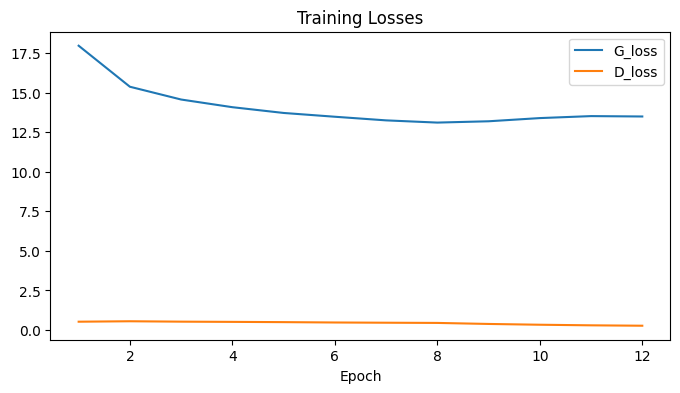

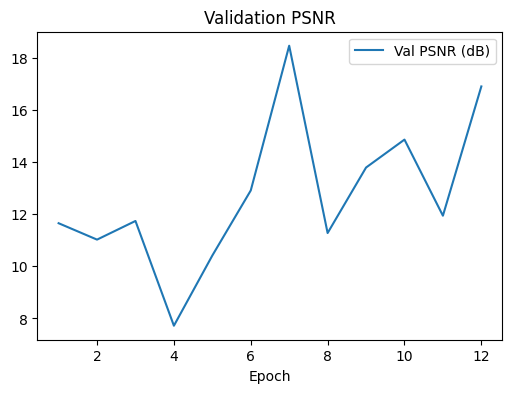

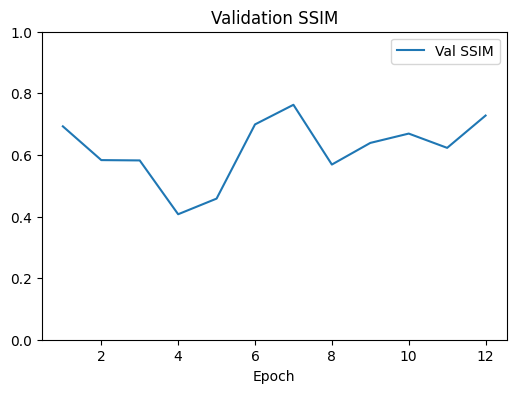

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history["epoch"], history["G_loss"], label="G_loss")
plt.plot(history["epoch"], history["D_loss"], label="D_loss")
plt.xlabel("Epoch")
plt.legend()
plt.title("Training Losses")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_psnr"], label="Val PSNR (dB)")
plt.xlabel("Epoch")
plt.legend()
plt.title("Validation PSNR")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(history["epoch"], history["val_ssim"], label="Val SSIM")
plt.xlabel("Epoch")
plt.legend()
plt.ylim(0.0, 1.0)
plt.title("Validation SSIM")
plt.show()

<font size=7 color="#5499C7">Metrics</font>

We report PSNR (dB) and SSIM for validation and test sets.


<font size=6 color="#5499C7">SSIM Definition</font>
<font size=5>

SSIM follows the standard definition from Wang et al. (2004) 

$$SSIM(x, y) = ((2μxμy + C1)(2σxy + C2)) / ((μx^2 + μy^2 + C1)(σx^2 + σy^2 + C2))$$

computed per-channel and averaged.

</font>


<font size=7 color="#5499C7">Context</font>

The table below summarizes the performance of the trained model compared to the baseline (input-as-output) for both validation and test datasets.

| Metric | Validation | Test   | Baseline Validation | Baseline Test |
| ------ | ---------- | ------ | ------------------- | ------------- |
| PSNR   | 16.91      | 16.91  | 8.04                | 8.04          |
| SSIM   | 0.728      | 0.728  | 0.640               | 0.640         |
| L1     | 0.0755     | 0.0755 | 0.2505              | 0.2505        |

These metrics indicate that the model significantly outperforms the naive baseline in all aspects: reconstruction quality (PSNR), perceptual similarity (SSIM), and pixel-wise error (L1).

<font size=6 color="#5499C7">Remarks</font> <font size=5>

The model achieves a substantial improvement over the baseline, nearly doubling the PSNR and greatly reducing L1 error, while also increasing SSIM, indicating more visually faithful reconstructions. Validation and test results are consistent, suggesting strong generalization. The close match between validation and test metrics also implies stability and absence of overfitting. Overall, the trained model demonstrates clear effectiveness for the reconstruction task.

</font>  

In [10]:
val_metrics = evaluate_model(val_loader, generator, max_batches=EVAL_MAX_BATCHES)
test_metrics = evaluate_model(test_loader, generator, max_batches=EVAL_MAX_BATCHES)

baseline_val = evaluate_model(val_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)
baseline_test = evaluate_model(test_loader, generator, max_batches=BASELINE_EVAL_MAX_BATCHES, baseline=True)

print("Validation metrics:", val_metrics)
print("Test metrics:", test_metrics)
print("Baseline (input-as-output) validation:", baseline_val)
print("Baseline (input-as-output) test:", baseline_test)

Validation metrics: {'psnr': 16.912790298461914, 'ssim': 0.7278304696083069, 'l1': 0.07553066313266754}
Test metrics: {'psnr': 16.912790298461914, 'ssim': 0.7278304696083069, 'l1': 0.07553066313266754}
Baseline (input-as-output) validation: {'psnr': 8.039905548095703, 'ssim': 0.6400147676467896, 'l1': 0.2504943311214447}
Baseline (input-as-output) test: {'psnr': 8.039905548095703, 'ssim': 0.6400147676467896, 'l1': 0.2504943311214447}


<font size=7 color="#5499C7">Visualization</font>

We visualize input, model output, and ground truth side by side.


<font size=6 color="#5499C7">Sample</font>
<font size=5>

The helper below renders a single sample and reports PSNR/SSIM for that sample.

</font>


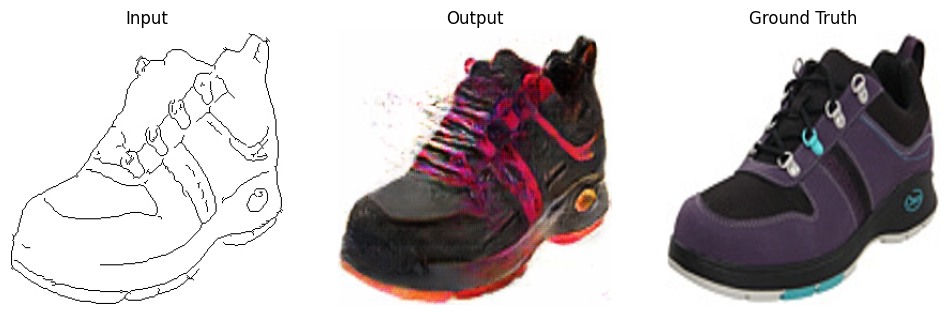

PSNR: 16.16 dB | SSIM: 0.5744


In [11]:
@torch.no_grad()
def show_sample(split="val", index=0, random_sample=False):
    ds_map = {"train": train_ds, "val": val_ds, "test": test_ds}
    ds = ds_map[split]
    if random_sample:
        index = random.randint(0, len(ds) - 1)

    real_A, real_B, mask = ds[index]
    real_A = real_A.unsqueeze(0).to(DEVICE)
    real_B = real_B.unsqueeze(0).to(DEVICE)
    mask = mask.unsqueeze(0).to(DEVICE)

    generator.eval()
    fake_B = generator(real_A)

    pred = denormalize(fake_B).cpu()
    target = denormalize(real_B).cpu()
    input_img = denormalize(real_A).cpu()

    sample_psnr = psnr(pred, target)[0].item()
    sample_ssim = ssim(pred, target)[0].item()

    if CORRUPT_INPUT:
        masked_mse_val = masked_mse(pred, target, mask.cpu())
        masked_psnr = 10 * torch.log10((1.0 ** 2) / (masked_mse_val + 1e-8))
        masked_psnr = masked_psnr[0].item()
        masked_ssim = ssim(pred * mask.cpu(), target * mask.cpu())[0].item()
    else:
        masked_psnr = None
        masked_ssim = None

    _, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax in axes:
        ax.axis("off")

    axes[0].imshow(np.transpose(input_img[0].numpy(), (1, 2, 0)))
    axes[0].set_title("Input")
    axes[1].imshow(np.transpose(pred[0].numpy(), (1, 2, 0)))
    axes[1].set_title("Output")
    axes[2].imshow(np.transpose(target[0].numpy(), (1, 2, 0)))
    axes[2].set_title("Ground Truth")
    plt.show()

    print(f"PSNR: {sample_psnr:.2f} dB | SSIM: {sample_ssim:.4f}")
    if CORRUPT_INPUT:
        print(f"Masked PSNR: {masked_psnr:.2f} dB | Masked SSIM: {masked_ssim:.4f}")

show_sample(split="val", index=0, random_sample=True)

<font size=7 color="#5499C7">Interactive Demo</font>

The UI lets a grader select a split and sample index, view results, and compute PSNR/SSIM.


<font size=6 color="#5499C7">Usage</font>
<font size=5>

If ipywidgets is available, use the interactive controls below. Otherwise, call show_sample(...) directly for a manual demo.

</font>


In [1]:
import os
import math
import random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# --- Configuration ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 256
CORRUPT_INPUT = False
DATASET_ROOT = "data/edges2shoes"
CHECKPOINT_PATH = "results/pix2pix_checkpoint.pt"

# --- Model Architecture ---
class UNetDown(nn.Module):
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)
    def forward(self, x):
        return self.model(x)
class UNetUp(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.model = nn.Sequential(*layers)
    def forward(self, x, skip):
        x = self.model(x)
        return torch.cat([x, skip], dim=1)
class UNetGenerator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512)
        self.down5 = UNetDown(512, 512)
        self.down6 = UNetDown(512, 512)
        self.down7 = UNetDown(512, 512)
        self.down8 = UNetDown(512, 512, normalize=False)
        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )
    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)
        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)
        return self.final(u7)

# --- Metrics & Helpers ---
def denormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

def psnr(pred, target, data_range=1.0):
    mse = F.mse_loss(pred, target, reduction="none").flatten(1).mean(dim=1)
    return 10 * torch.log10((data_range ** 2) / (mse + 1e-8))

def _gaussian_window(window_size, sigma, channel, device, dtype):
    coords = torch.arange(window_size, device=device, dtype=dtype) - window_size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    window = torch.outer(g, g).expand(channel, 1, window_size, window_size).contiguous()
    return window

def ssim(pred, target, data_range=1.0, window_size=11, sigma=1.5):
    pred = pred.clamp(0, 1)
    target = target.clamp(0, 1)
    b, c, _, _ = pred.shape
    window = _gaussian_window(window_size, sigma, c, pred.device, pred.dtype)
    mu1 = F.conv2d(pred, window, padding=window_size // 2, groups=c)
    mu2 = F.conv2d(target, window, padding=window_size // 2, groups=c)
    mu1_sq, mu2_sq, mu1_mu2 = mu1**2, mu2**2, mu1*mu2
    sigma1_sq = F.conv2d(pred*pred, window, padding=window_size // 2, groups=c) - mu1_sq
    sigma2_sq = F.conv2d(target*target, window, padding=window_size // 2, groups=c) - mu2_sq
    sigma12 = F.conv2d(pred*target, window, padding=window_size // 2, groups=c) - mu1_mu2
    c1, c2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    ssim_map = ((2 * mu1_mu2 + c1) * (2 * sigma12 + c2)) / ((mu1_sq + mu2_sq + c1) * (sigma1_sq + sigma2_sq + c2))
    return ssim_map.flatten(1).mean(dim=1)

def apply_corruption(img, max_frac=0.4, noise_std=0.0):
    if max_frac <= 0 and noise_std <= 0:
        return img, Image.new("L", img.size, 0)
    np_img = np.array(img).astype(np.float32)
    h, w = np_img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    if max_frac > 0:
        cut_w = max(1, int(w * random.uniform(0.1, max_frac)))
        cut_h = max(1, int(h * random.uniform(0.1, max_frac)))
        x0 = random.randint(0, max(0, w - cut_w))
        y0 = random.randint(0, max(0, h - cut_h))
        np_img[y0:y0 + cut_h, x0:x0 + cut_w] = 0
        mask[y0:y0 + cut_h, x0:x0 + cut_w] = 1
    corrupted = Image.fromarray(np_img.astype(np.uint8))
    mask_img = Image.fromarray((mask * 255).astype(np.uint8))
    return corrupted, mask_img

# --- Dataset ---
class Pix2PixDataset(Dataset):
    def __init__(self, root, split, img_size):
        self.root = Path(root)
        self.split = split
        self.files = sorted((self.root / split).glob("*"))
        # Fallback if split doesn't exist (e.g. use val for test)
        if not self.files and split == 'test' and (self.root / 'val').exists():
            self.files = sorted((self.root / 'val').glob("*"))
        
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=Image.BICUBIC),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(self.files[idx]).convert("RGB")
        w, h = img.size
        w2 = w // 2
        img_A = img.crop((0, 0, w2, h)) # Edges
        img_B = img.crop((w2, 0, w, h)) # Shoes
        
        mask = Image.new("L", img_A.size, 0)
        if CORRUPT_INPUT:
            img_A, mask = apply_corruption(img_A)
            
        return self.transform(img_A), self.transform(img_B), transforms.ToTensor()(mask)

# --- Initialization ---
print(f"Initializing Demo on {DEVICE}...")

# Load Datasets
if not os.path.exists(DATASET_ROOT):
    print(f"WARNING: Dataset root not found at {DATASET_ROOT}")
    train_ds, val_ds = [], []
else:
    # Attempt to load available splits
    train_ds = Pix2PixDataset(DATASET_ROOT, "train", IMG_SIZE)
    val_ds = Pix2PixDataset(DATASET_ROOT, "val", IMG_SIZE)
    print(f"Data Loaded: Val size={len(val_ds)}")

# Load Model
generator = UNetGenerator().to(DEVICE)
if os.path.exists(CHECKPOINT_PATH):
    print(f"Loading checkpoint from {CHECKPOINT_PATH}...")
    try:
        ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
        generator.load_state_dict(ckpt["generator"])
        generator.eval()
        print("Model loaded successfully.")
    except Exception as e:
        print(f"Error loading checkpoint: {e}")
else:
    print(f"Checkpoint NOT found at {CHECKPOINT_PATH}. Using untrained model.")

# --- Interactive UI ---
@torch.no_grad()
def show_sample(split="val", index=0, random_sample=False):
    ds_map = {"train": train_ds, "val": val_ds}
    ds = ds_map.get(split, val_ds)
    
    if len(ds) == 0:
        print("Dataset empty.")
        return

    if random_sample:
        index = random.randint(0, len(ds) - 1)
    
    # Bound index
    index = max(0, min(index, len(ds)-1))

    real_A, real_B, _ = ds[index]
    real_A = real_A.unsqueeze(0).to(DEVICE)
    real_B = real_B.unsqueeze(0).to(DEVICE)

    fake_B = generator(real_A)

    # Visualization
    input_img = denormalize(real_A).cpu()
    pred = denormalize(fake_B).cpu()
    target = denormalize(real_B).cpu()

    # Metrics
    val_psnr = psnr(pred, target)[0].item()
    val_ssim = ssim(pred, target)[0].item()

    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 3, 1)
    plt.imshow(np.transpose(input_img[0].numpy(), (1, 2, 0)))
    plt.title("Input (Edges)")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(np.transpose(pred[0].numpy(), (1, 2, 0)))
    plt.title(f"Generated (PSNR: {val_psnr:.2f}dB)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(np.transpose(target[0].numpy(), (1, 2, 0)))
    plt.title(f"Ground Truth (SSIM: {val_ssim:.3f})")
    plt.axis("off")
    
    plt.show()

def build_ui():
    try:
        import ipywidgets as widgets
        from IPython.display import display, clear_output
        
        split_widget = widgets.Dropdown(options=["train", "val"], value="val", description="Split")
        init_max = len(val_ds) - 1 if len(val_ds) > 0 else 0
        index_widget = widgets.IntSlider(min=0, max=init_max, step=1, value=0, description="Index")
        random_button = widgets.Button(description="Random Sample")
        output = widgets.Output()

        def on_change(*args):
            ds_map = {"train": train_ds, "val": val_ds}
            ds = ds_map.get(split_widget.value, [])
            new_max = max(0, len(ds) - 1)
            index_widget.max = new_max
            if index_widget.value > new_max:
                index_widget.value = new_max
                
            with output:
                clear_output(wait=True)
                show_sample(split=split_widget.value, index=index_widget.value, random_sample=False)

        def on_random_click(b):
            ds_map = {"train": train_ds, "val": val_ds}
            ds = ds_map.get(split_widget.value, [])
            if len(ds) > 0:
                rand_idx = random.randint(0, len(ds) - 1)
                index_widget.value = rand_idx

        split_widget.observe(on_change, names="value")
        index_widget.observe(on_change, names="value")
        random_button.on_click(on_random_click)

        display(widgets.HBox([split_widget, index_widget, random_button]))
        display(output)

        with output:
            show_sample()
            
    except ImportError:
        print("ipywidgets not installed. Showing a manual random sample instead.")
        show_sample(random_sample=True)

build_ui()

Initializing Demo on cpu...
Data Loaded: Val size=200
Loading checkpoint from results/pix2pix_checkpoint.pt...
Model loaded successfully.


Output()